# Program 1 - EDA (Stroke Prediction Dataset)

## Langkah 1. Import library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Langkah 2. Baca dataset dan tampilkan data

In [2]:
df = pd.read_csv('Dataset_pert_2.xls')   # file berformat CSV
print(df.shape)
df.head(10)

(5110, 12)
      id  gender   age  hypertension  heart_disease ever_married      work_type Residence_type  avg_glucose_level   bmi   smoking_status  stroke
0   9046    Male  67.0             0              1          Yes        Private          Urban             228.69  36.6  formerly smoked       1
1  51676  Female  61.0             0              0          Yes  Self-employed          Rural             202.21   NaN     never smoked       1
2  31112    Male  80.0             0              1          Yes        Private          Rural             105.92  32.5     never smoked       1
3  60182  Female  49.0             0              0          Yes        Private          Urban             171.23  34.4           smokes       1
4   1665  Female  79.0             1              0          Yes  Self-employed          Rural             174.12  24.0     never smoked       1
5  56669    Male  81.0             0              0          Yes        Private          Urban             186.21  29.0

## Langkah 3. Informasi data (info)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


## Langkah 4. Deskripsi statistik (describe)

In [4]:
df.describe()

                 id          age  hypertension  heart_disease  avg_glucose_level          bmi       stroke
count   5110.000000  5110.000000   5110.000000    5110.000000        5110.000000  4909.000000  5110.000000
mean   36517.829354    43.226614      0.097456       0.054012         106.147677    28.893237     0.048728
std    21161.721625    22.612647      0.296607       0.226063          45.283560     7.854067     0.215320
min       67.000000     0.080000      0.000000       0.000000          55.120000    10.300000     0.000000
25%    17741.250000    25.000000      0.000000       0.000000          77.245000    23.500000     0.000000
50%    36932.000000    45.000000      0.000000       0.000000          91.885000    28.100000     0.000000
75%    54682.000000    61.000000      0.000000       0.000000         114.090000    33.100000     0.000000
max    72940.000000    82.000000      1.000000       1.000000         271.740000    97.600000     1.000000


## Langkah 5. Hitung data kosong tiap kolom

In [5]:
df.isna().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


## Langkah 6. Isi unik kolom kategorik

In [6]:
kategorik = df.select_dtypes(exclude='number').columns
for kol in kategorik:
    print(kol, '->', df[kol].unique().tolist())

gender -> ['Male', 'Female', 'Other']
ever_married -> ['Yes', 'No']
work_type -> ['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Residence_type -> ['Urban', 'Rural']
smoking_status -> ['formerly smoked', 'never smoked', 'smokes', 'Unknown']


## Langkah 7. Isi data kosong (modus & mean)

In [7]:
for kol in df.columns:
    if not pd.api.types.is_numeric_dtype(df[kol]):
        df[kol] = df[kol].fillna(df[kol].mode()[0])
    else:
        df[kol] = df[kol].fillna(df[kol].mean())
print(df.isna().sum().sum(), 'data kosong tersisa')

0 data kosong tersisa


## Langkah 8. Hitung data duplikat

In [8]:
print('Jumlah duplikat:', df.duplicated().sum())

Jumlah duplikat: 0


## Langkah 9. Hapus duplikat dan cek dengan info()

In [9]:
df = df.drop_duplicates()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                5110 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


## Langkah 10. Visualisasi grafik batang

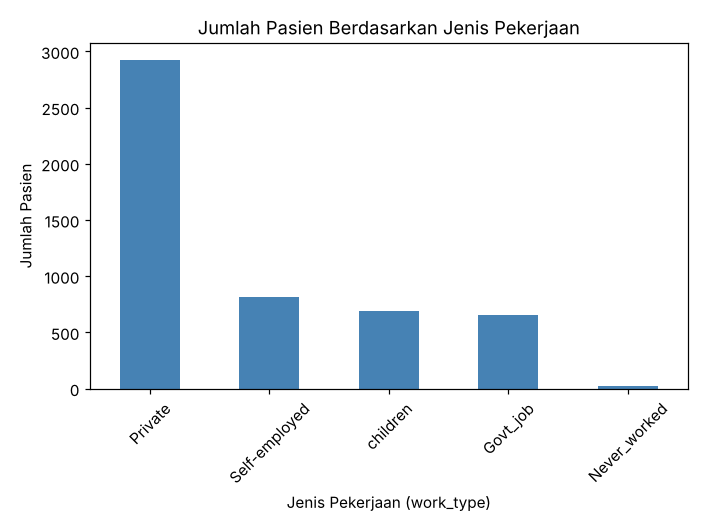

In [10]:
jumlah = df['work_type'].value_counts()
jumlah.plot(kind='bar', color='steelblue')
plt.title('Jumlah Pasien Berdasarkan Jenis Pekerjaan')
plt.xlabel('Jenis Pekerjaan (work_type)')
plt.ylabel('Jumlah Pasien')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Program 5 - Naive Bayes (student-por)

## Langkah 1. Import library

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

## Langkah 2. Baca dataset dan tampilkan data (head)

In [12]:
df = pd.read_csv('student-por.csv')
# target kategori: lulus jika nilai akhir G3 >= 10
df['hasil'] = np.where(df['G3'] >= 10, 'lulus', 'tidak lulus')
df = df.drop(columns=['G3'])
print(df.shape)
df.head()

(649, 33)
  school sex  age address famsize Pstatus  Medu  ...  Dalc Walc health absences  G1  G2  hasil
0     GP   F   18       U     GT3       A     4  ...     1    1      3        4   0  11  lulus
1     GP   F   17       U     GT3       T     1  ...     1    1      3        2   9  11  lulus
2     GP   F   15       U     LE3       T     1  ...     2    3      3        6  12  13  lulus
3     GP   F   15       U     GT3       T     4  ...     1    1      5        0  14  14  lulus
4     GP   F   16       U     GT3       T     3  ...     1    2      5        0  11  13  lulus


## Langkah 3. Informasi data dan deskripsi statistik

In [13]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

## Langkah 4. Pisahkan fitur numerik

In [14]:
fitur_num = df.select_dtypes(include=np.number).columns.tolist()
print('Jumlah fitur numerik:', len(fitur_num))
print(fitur_num)

Jumlah fitur numerik: 15
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


## Langkah 5. Pisahkan fitur kategorikal

In [15]:
fitur_kat = df.select_dtypes(exclude=np.number).columns.tolist()
print('Jumlah fitur kategorikal:', len(fitur_kat))
print(fitur_kat)

Jumlah fitur kategorikal: 18
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'hasil']


## Langkah 6. Isi unik tiap fitur kategorikal

In [16]:
for kol in fitur_kat:
    print(kol, '->', df[kol].unique().tolist())

school -> ['GP', 'MS']
sex -> ['F', 'M']
address -> ['U', 'R']
famsize -> ['GT3', 'LE3']
Pstatus -> ['A', 'T']
Mjob -> ['at_home', 'health', 'other', 'services', 'teacher']
Fjob -> ['teacher', 'other', 'services', 'health', 'at_home']
reason -> ['course', 'other', 'home', 'reputation']
guardian -> ['mother', 'father', 'other']
schoolsup -> ['yes', 'no']
famsup -> ['no', 'yes']
paid -> ['no', 'yes']
activities -> ['no', 'yes']
nursery -> ['yes', 'no']
higher -> ['yes', 'no']
internet -> ['no', 'yes']
romantic -> ['no', 'yes']
hasil -> ['lulus', 'tidak lulus']


## Langkah 7. LabelEncoder fitur kategorikal

In [17]:
le = LabelEncoder()
# kolom 'hasil' ikut diubah: 0 = lulus, 1 = tidak lulus
for kol in fitur_kat:
    df[kol] = le.fit_transform(df[kol])
df.head()

   school  sex  age  address  famsize  Pstatus  Medu  ...  Dalc  Walc  health  absences  G1  G2  hasil
0       0    0   18        1        0        0     4  ...     1     1       3         4   0  11      0
1       0    0   17        1        0        1     1  ...     1     1       3         2   9  11      0
2       0    0   15        1        1        1     1  ...     2     3       3         6  12  13      0
3       0    0   15        1        0        1     4  ...     1     1       5         0  14  14      0
4       0    0   16        1        0        1     3  ...     1     2       5         0  11  13      0


## Langkah 8. Pisahkan fitur x dan target y, bagi data

In [18]:
x = df.drop(columns=['hasil'])
y = df['hasil']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0)
print('Data latih:', x_train.shape, '| Data uji:', x_test.shape)

Data latih: (486, 32) | Data uji: (163, 32)


## Langkah 9. Buat model GaussianNB, latih, dan prediksi

In [19]:
model = GaussianNB()
model.fit(x_train, y_train)
pred_train = model.predict(x_train)
pred_test = model.predict(x_test)

## Langkah 10. Evaluasi data latih

Evaluasi Training
[[362  44]
 [ 14  66]]
              precision    recall  f1-score   support

           0       0.96      0.89      0.93       406
           1       0.60      0.82      0.69        80

    accuracy                           0.88       486
   macro avg       0.78      0.86      0.81       486
weighted avg       0.90      0.88      0.89       486



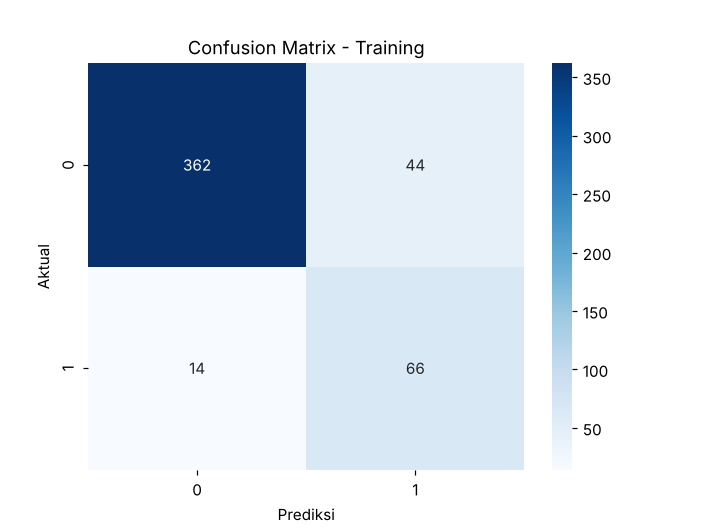

In [20]:
print('Evaluasi Training')
cm = confusion_matrix(y_train, pred_train)
print(cm)
print(classification_report(y_train, pred_train))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Training')
plt.xlabel('Prediksi'); plt.ylabel('Aktual')
plt.show()

## Langkah 11. Evaluasi data uji

Evaluasi Testing
[[128  15]
 [  6  14]]
              precision    recall  f1-score   support

           0       0.96      0.90      0.92       143
           1       0.48      0.70      0.57        20

    accuracy                           0.87       163
   macro avg       0.72      0.80      0.75       163
weighted avg       0.90      0.87      0.88       163



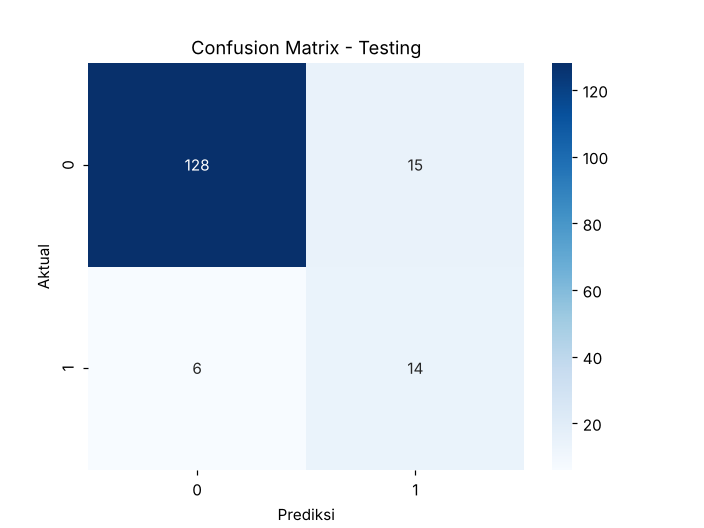

In [21]:
print('Evaluasi Testing')
cm = confusion_matrix(y_test, pred_test)
print(cm)
print(classification_report(y_test, pred_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Testing')
plt.xlabel('Prediksi'); plt.ylabel('Aktual')
plt.show()

## Langkah 12. Uji dengan 1 data baru

In [22]:
data_baru = x_test.iloc[[0]]
print('Hasil prediksi:', model.predict(data_baru)[0])
print('Label aktual  :', y_test.iloc[0])

Hasil prediksi: 1
Label aktual  : 1
